# EntityExtract exploratory data analysis
Executed on 12 October 2026. Original eda.ipynb was empty. The original bert.ipynb is preserved.
Scores below are historical reproduction on shortened silver sequences, not full-context human-gold accuracy.


In [1]:
from pathlib import Path
import pandas as pd
import json
ROOT = Path.cwd()
df = pd.read_csv(ROOT / 'data.csv')
catalog = pd.read_csv(ROOT / 'products_labeled.csv')
print('Rows and columns:', df.shape)
print(df.head(3)[['product_name','brand']].to_string(index=False))


Rows and columns: (20000, 15)
                       product_name        brand
Alisha Solid Women's Cycling Shorts       Alisha
FabHomeDecor Fabric Double Sofa Bed FabHomeDecor
                         AW Bellies           AW


In [2]:
normalized = df.description.dropna().str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
print('Missing descriptions:', df.description.isna().sum())
print('Duplicate nonmissing descriptions:', normalized.duplicated().sum())
print('Attribute missing counts in recommendation catalog:')
print(catalog[['color','material','dimensions','weight']].isna().sum().to_string())
manifest = json.loads((ROOT/'artifacts/prepared/manifest.json').read_text(encoding='utf-8'))
print('New full-context split:', manifest['split_sizes'])


Missing descriptions: 2
Duplicate nonmissing descriptions: 1807
Attribute missing counts in recommendation catalog:
color          3321
material       8018
dimensions    17789
weight        10169
New full-context split: {'train': 12733, 'validation': 2728, 'test': 2730}


Mean full description words: 72.77
Median full description words: 42


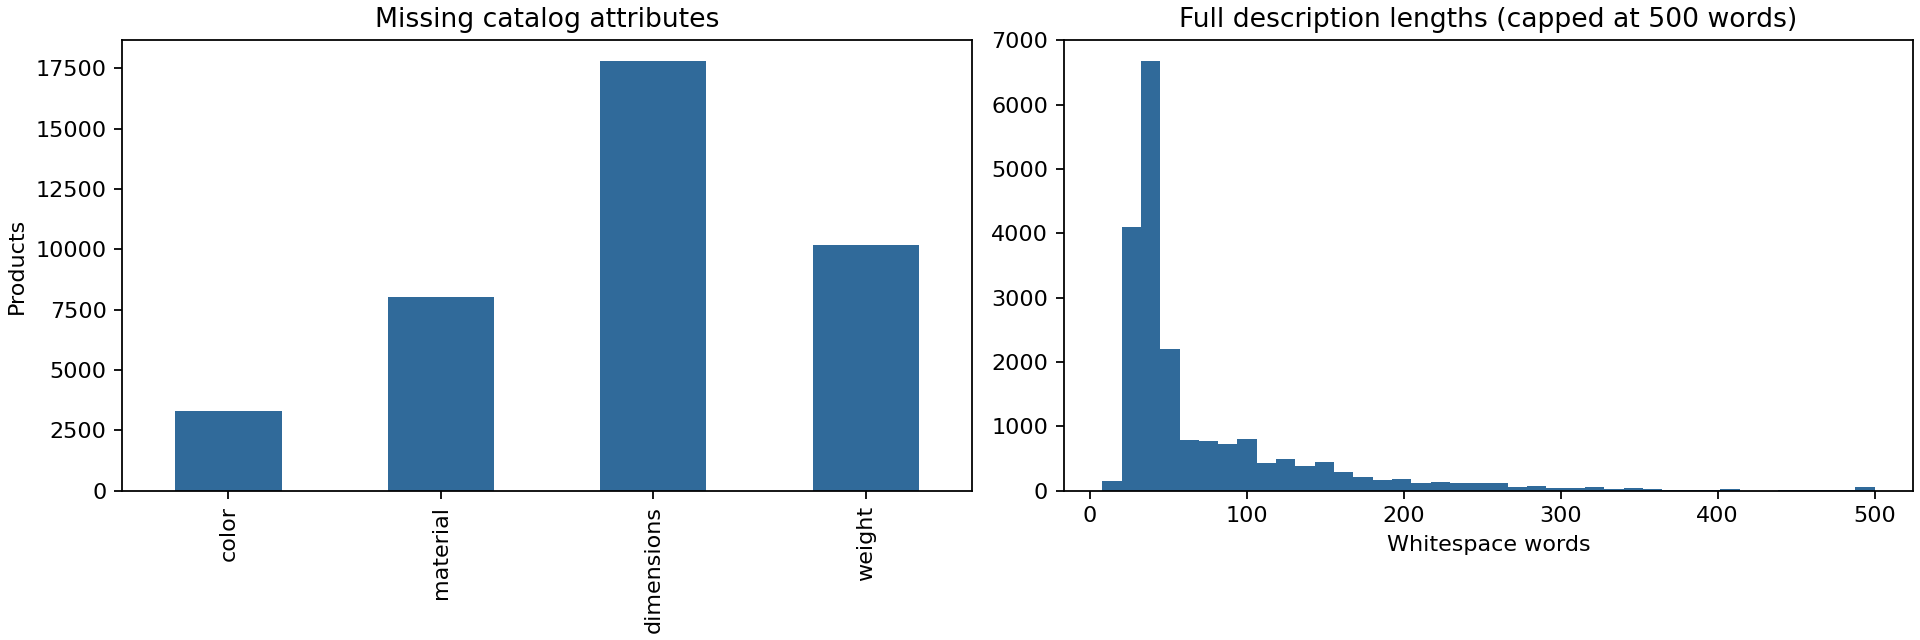

In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
catalog[['color','material','dimensions','weight']].isna().sum().plot.bar(ax=axes[0], color='#306a9a')
axes[0].set_title('Missing catalog attributes')
axes[0].set_ylabel('Products')
lengths = df.description.dropna().str.split().str.len()
axes[1].hist(lengths.clip(upper=500), bins=40, color='#306a9a')
axes[1].set_title('Full description lengths (capped at 500 words)')
axes[1].set_xlabel('Whitespace words')
(ROOT/'artifacts/eda').mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT/'artifacts/eda/data_overview.png', dpi=160)
print('Mean full description words:', round(lengths.mean(), 2))
print('Median full description words:', int(lengths.median()))
plt.close(fig)


In [4]:
metrics = json.loads((ROOT/'artifacts/legacy-evaluation/metrics.json').read_text(encoding='utf-8'))
print('Legacy weighted token F1:', metrics['token_report']['weighted avg']['f1-score'])
print('Legacy strict subword entity micro F1:', metrics['entity_micro']['f1'])
print(pd.DataFrame(metrics['per_attribute']).T[['precision','recall','f1','support']].to_string())
print('References are shortened silver labels, not independent human gold.')


Legacy weighted token F1: 0.9655020224404347
Legacy strict subword entity micro F1: 0.9072164948453608
            precision    recall        f1  support
Color        0.880260  0.973265  0.924429   3890.0
Material     0.866304  0.963336  0.912247   2482.0
Dimensions   0.620253  0.989899  0.762646     99.0
Weight       0.731358  0.975765  0.836066    784.0
References are shortened silver labels, not independent human gold.
